# Task 1 — Data Science Fundamentals Assessment
**YuvaIntern · Data Analyst Internship**
**Intern:** Rashad Kazi 

This notebook works through the core fundamentals of data science in five parts:

1. Python basics
2. Data types (Python, NumPy/Pandas, and statistical data types)
3. Statistical foundations, applied to the real-world Iris dataset
4. Industry best practices
5. Fundamentals assignment (10 questions, answered with code)

In [1]:
import os
import math
import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_iris

os.makedirs("figures", exist_ok=True)
np.random.seed(42)          # reproducible results
pd.set_option("display.precision", 3)
print("NumPy", np.__version__, "| Pandas", pd.__version__)

NumPy 2.5.3 | Pandas 3.0.5


## Part 1 — Python Basics
### 1.1 Variables and built-in data types

In [2]:
name = "Data Analyst"        # str
tasks = 6                    # int
progress = 0.0               # float
is_active = True             # bool
skills = ["Python", "Pandas", "Statistics"]           # list  (ordered, mutable)
duration = (18, "Sep", 2026)                           # tuple (ordered, immutable)
intern = {"role": name, "tasks": tasks}                # dict  (key -> value)
tools = {"Python", "Jupyter", "Python"}                # set   (unique values only)

for value in [name, tasks, progress, is_active, skills, duration, intern, tools]:
    print(f"{type(value).__name__:6} -> {value}")

str    -> Data Analyst
int    -> 6
float  -> 0.0
bool   -> True
list   -> ['Python', 'Pandas', 'Statistics']
tuple  -> (18, 'Sep', 2026)
dict   -> {'role': 'Data Analyst', 'tasks': 6}
set    -> {'Python', 'Jupyter'}


### 1.2 Control flow, functions and error handling

In [3]:
def grade(score):
    """Return a letter grade for a numeric score (0-100)."""
    if not isinstance(score, (int, float)):
        raise TypeError("score must be a number")
    if score >= 85:
        return "A"
    elif score >= 70:
        return "B"
    elif score >= 50:
        return "C"
    return "Fail"

marks = [92, 78, 55, 40, "absent"]
for m in marks:
    try:
        print(m, "->", grade(m))
    except TypeError as err:
        print(m, "-> error:", err)

92 -> A
78 -> B
55 -> C
40 -> Fail
absent -> error: score must be a number


### 1.3 List comprehensions, lambda and built-in functions

In [4]:
numbers = list(range(1, 11))
squares = [n ** 2 for n in numbers]
evens = [n for n in numbers if n % 2 == 0]
cubes = list(map(lambda n: n ** 3, numbers[:5]))

print("Squares:", squares)
print("Evens:  ", evens)
print("Cubes:  ", cubes)
print("Sum / Max / Min:", sum(numbers), max(numbers), min(numbers))

Squares: [1, 4, 9, 16, 25, 36, 49, 64, 81, 100]
Evens:   [2, 4, 6, 8, 10]
Cubes:   [1, 8, 27, 64, 125]
Sum / Max / Min: 55 10 1


## Part 2 — Data Types
### 2.1 NumPy arrays vs Python lists

In [5]:
py_list = [1, 2, 3, 4]
arr = np.array(py_list)

print("List * 2  :", py_list * 2)       # repeats the list
print("Array * 2 :", arr * 2)           # element-wise maths (vectorised)
print("Array dtype:", arr.dtype, "| shape:", arr.shape)

matrix = np.arange(1, 7).reshape(2, 3)
print("Matrix:\n", matrix)
print("Column means:", matrix.mean(axis=0))

List * 2  : [1, 2, 3, 4, 1, 2, 3, 4]
Array * 2 : [2 4 6 8]
Array dtype: int64 | shape: (4,)
Matrix:
 [[1 2 3]
 [4 5 6]]
Column means: [2.5 3.5 4.5]


### 2.2 Pandas dtypes

In [6]:
df_types = pd.DataFrame({
    "customer_id": [101, 102, 103, 104],
    "city": ["Pune", "Dharashiv", "Pune", "Latur"],
    "amount": [2500.50, 1800.00, 3200.75, 950.25],
    "is_member": [True, False, True, False],
    "order_date": pd.to_datetime(["2026-09-18", "2026-09-25", "2026-10-02", "2026-10-09"]),
    "rating": pd.Categorical(["Good", "Average", "Excellent", "Good"],
                             categories=["Poor", "Average", "Good", "Excellent"], ordered=True),
})
display(df_types)
print(df_types.dtypes)

,customer_id,city,amount,is_member,order_date,rating
0,101,Pune,2500.50,True,2026-09-18,Good
1,102,Dharashiv,1800.00,False,2026-09-25,Average
2,103,Pune,3200.75,True,2026-10-02,Excellent
3,104,Latur,950.25,False,2026-10-09,Good


customer_id             int64
city                      str
amount                float64
is_member                bool
order_date     datetime64[us]
rating               category
dtype: object


### 2.3 Statistical data types

| Type | Sub-type | Meaning | Example in the table above |
|---|---|---|---|
| Categorical (qualitative) | Nominal | Labels with no order | `city` |
| Categorical (qualitative) | Ordinal | Labels with a meaningful order | `rating` |
| Numerical (quantitative) | Discrete | Countable whole numbers | number of orders |
| Numerical (quantitative) | Continuous | Any value in a range | `amount` |

Numerical data is also described by its *scale*: **interval** (no true zero, e.g. temperature in °C) or **ratio** (true zero, e.g. amount in ₹).

## Part 3 — Statistical Foundations (Iris dataset)
The Iris dataset (R. A. Fisher, 1936; UCI Machine Learning Repository) has 150 flowers from 3 species with 4 measurements each.

In [7]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df = df.drop(columns="target")
df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]

print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))
display(df.head())

Shape: (150, 5)
Missing values: 0 | Duplicate rows: 1


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


There are no missing values. The one duplicate row is a genuine repeated measurement in the original dataset (two flowers with identical sizes), so it is kept.

### 3.1 Descriptive statistics — central tendency and spread

In [8]:
col = df["petal_length"]
summary = pd.Series({
    "Mean": col.mean(),
    "Median": col.median(),
    "Mode": col.mode()[0],
    "Variance": col.var(),
    "Std deviation": col.std(),
    "Range": col.max() - col.min(),
    "Q1 (25%)": col.quantile(0.25),
    "Q3 (75%)": col.quantile(0.75),
    "IQR": col.quantile(0.75) - col.quantile(0.25),
    "Skewness": col.skew(),
    "Kurtosis": col.kurt(),
}, name="petal_length")
display(summary.round(3).to_frame())
display(df.describe().round(2))

,petal_length
Mean,3.758
Median,4.350
Mode,1.400
Variance,3.116
Std deviation,1.765
Range,5.900
Q1 (25%),1.600
Q3 (75%),5.100
IQR,3.500
Skewness,-0.275


,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


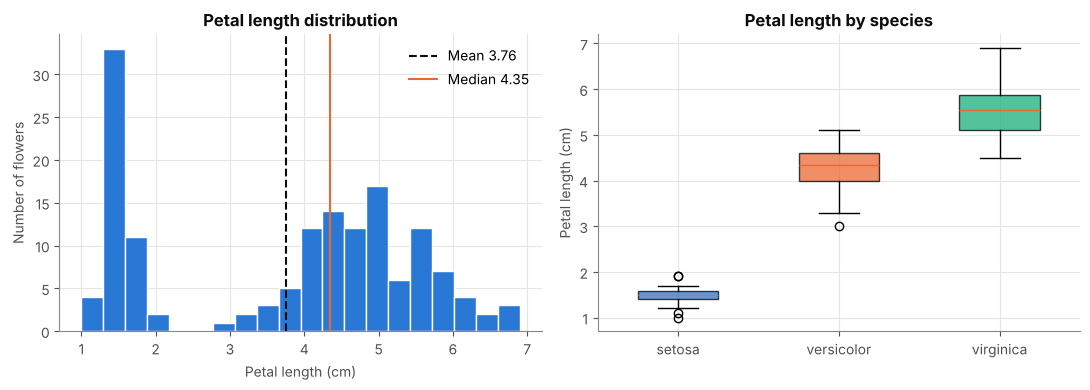

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["petal_length"], bins=20, color="#2a78d6", edgecolor="white")
axes[0].axvline(col.mean(), color="#0b0b0b", linestyle="--", linewidth=1.5, label=f"Mean {col.mean():.2f}")
axes[0].axvline(col.median(), color="#eb6834", linewidth=1.5, label=f"Median {col.median():.2f}")
axes[0].set_title("Petal length distribution")
axes[0].set_xlabel("Petal length (cm)"); axes[0].set_ylabel("Number of flowers")
axes[0].legend()

groups = [df.loc[df.species == s, "petal_length"] for s in iris.target_names]
bp = axes[1].boxplot(groups, tick_labels=list(iris.target_names), patch_artist=True, widths=0.5)
for patch, c in zip(bp["boxes"], ["#2a78d6", "#eb6834", "#1baf7a"]):
    patch.set_facecolor(c); patch.set_alpha(0.75)
axes[1].set_title("Petal length by species")
axes[1].set_ylabel("Petal length (cm)")
plt.tight_layout()
plt.savefig("figures/01_distribution_boxplot.png", dpi=150, bbox_inches="tight")

The histogram has two humps (bimodal): *setosa* forms a separate cluster of short petals, which pulls the mean (3.76) below the median (4.35).

### 3.2 Correlation

,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.00,-0.12,0.87,0.82
sepal_width,-0.12,1.00,-0.43,-0.37
petal_length,0.87,-0.43,1.00,0.96
petal_width,0.82,-0.37,0.96,1.00


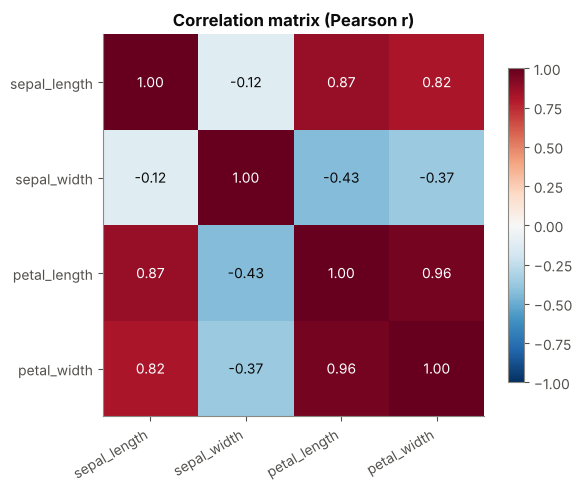

In [10]:
corr = df.drop(columns="species").corr().round(2)
display(corr)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(corr.columns, rotation=30, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels(corr.columns)
ax.grid(False)
for i in range(4):
    for j in range(4):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if abs(v) > 0.6 else "#0b0b0b")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation matrix (Pearson r)")
plt.tight_layout()
plt.savefig("figures/02_correlation_heatmap.png", dpi=150, bbox_inches="tight")

Petal length and petal width are almost perfectly correlated (r = 0.96). Sepal width has a weak negative relation with the other measurements.

### 3.3 Normal distribution and the Central Limit Theorem
Even when the population is skewed, the means of repeated samples form a bell-shaped (normal) curve.

Population mean = 1.992, mean of sample means = 2.011
Theoretical standard error = 0.314, observed = 0.311


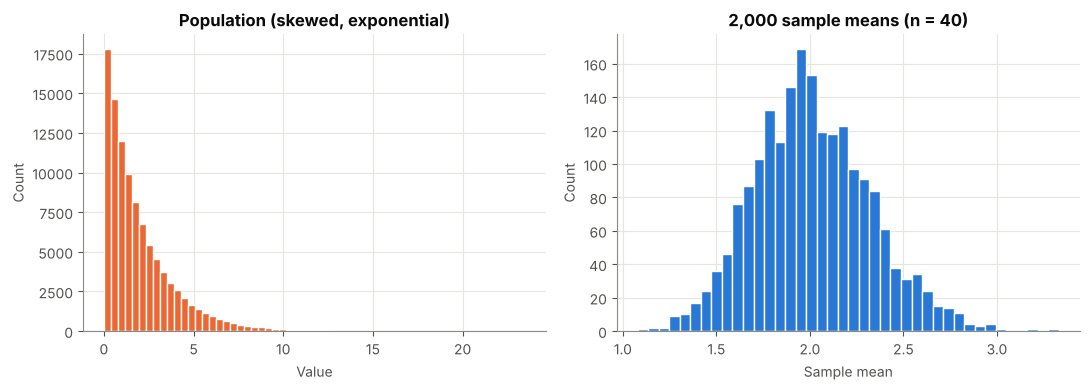

In [11]:
population = np.random.exponential(scale=2.0, size=100_000)       # right-skewed population
sample_means = [np.random.choice(population, 40).mean() for _ in range(2_000)]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(population, bins=60, color="#eb6834", edgecolor="white")
axes[0].set_title("Population (skewed, exponential)")
axes[0].set_xlabel("Value"); axes[0].set_ylabel("Count")
axes[1].hist(sample_means, bins=40, color="#2a78d6", edgecolor="white")
axes[1].set_title("2,000 sample means (n = 40)")
axes[1].set_xlabel("Sample mean"); axes[1].set_ylabel("Count")
plt.tight_layout()
plt.savefig("figures/03_central_limit_theorem.png", dpi=150, bbox_inches="tight")

print(f"Population mean = {population.mean():.3f}, mean of sample means = {np.mean(sample_means):.3f}")
print(f"Theoretical standard error = {population.std()/math.sqrt(40):.3f}, observed = {np.std(sample_means):.3f}")

### 3.4 Confidence interval and hypothesis test
**Question:** Is the mean sepal length of *versicolor* different from *virginica*?  
H₀: the two means are equal · H₁: the means differ · significance level α = 0.05

In [12]:
versicolor = df.loc[df.species == "versicolor", "sepal_length"]
virginica = df.loc[df.species == "virginica", "sepal_length"]

def ci95(x):
    se = x.std(ddof=1) / math.sqrt(len(x))
    t_crit = stats.t.ppf(0.975, df=len(x) - 1)
    return x.mean() - t_crit * se, x.mean() + t_crit * se

for label, x in [("versicolor", versicolor), ("virginica", virginica)]:
    lo, hi = ci95(x)
    print(f"{label:10}: mean = {x.mean():.3f} cm, 95% CI = ({lo:.3f}, {hi:.3f})")

t_stat, p_value = stats.ttest_ind(versicolor, virginica, equal_var=False)   # Welch's t-test
print(f"\nWelch t = {t_stat:.3f}, p-value = {p_value:.2e}")
print("Decision:", "Reject H0 - the means differ" if p_value < 0.05 else "Fail to reject H0")

versicolor: mean = 5.936 cm, 95% CI = (5.789, 6.083)
virginica : mean = 6.588 cm, 95% CI = (6.407, 6.769)

Welch t = -5.629, p-value = 1.87e-07
Decision: Reject H0 - the means differ


## Part 4 — Industry Best Practices

| Area | Practice followed in this notebook |
|---|---|
| Reproducibility | Fixed random seed (`np.random.seed(42)`), library versions printed, all steps in code |
| Project lifecycle | CRISP-DM: business understanding → data understanding → preparation → modelling → evaluation → deployment |
| Data quality | Checked shape, missing values and duplicates before analysis |
| Readable code | PEP 8 naming, small functions with docstrings, comments where logic is not obvious |
| Version control | Notebook, figures and README kept in a Git repository on GitHub |
| Correct statistics | Welch's t-test (does not assume equal variance); report effect + p-value, not just "significant" |
| Ethics & privacy | Public, anonymous dataset; no personal data; results reported honestly with limitations |
| Communication | Every chart has a title, axis labels and units; findings written in plain language |

## Part 5 — Fundamentals Assignment
**Q1. Write a function that returns the mean, median and standard deviation of a list without using NumPy.**

In [13]:
def basic_stats(values):
    n = len(values)
    mean = sum(values) / n
    s = sorted(values)
    median = s[n // 2] if n % 2 else (s[n // 2 - 1] + s[n // 2]) / 2
    std = math.sqrt(sum((v - mean) ** 2 for v in values) / (n - 1))   # sample std
    return round(mean, 3), median, round(std, 3)

data = [12, 15, 11, 18, 20, 15, 14]
print("Mine      :", basic_stats(data))
print("statistics:", (round(statistics.mean(data), 3), statistics.median(data), round(statistics.stdev(data), 3)))

Mine      : (15.0, 15, 3.162)
statistics: (15, 15, 3.162)


**Q2. Count how many flowers of each species have petal length above the overall mean.**

In [14]:
above = df[df.petal_length > df.petal_length.mean()]
print(above.species.value_counts())

species
virginica     50
versicolor    43
Name: count, dtype: int64


**Q3. Detect outliers in `sepal_width` using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR).**

In [15]:
q1, q3 = df.sepal_width.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(df.sepal_width < low) | (df.sepal_width > high)]
print(f"Bounds: {low:.2f} to {high:.2f} | Outliers found: {len(outliers)}")
display(outliers[["sepal_width", "species"]])

Bounds: 2.05 to 4.05 | Outliers found: 4


,sepal_width,species
15,4.4,setosa
32,4.1,setosa
33,4.2,setosa
60,2.0,versicolor


**Q4. Standardise petal length to z-scores and confirm mean ≈ 0 and std ≈ 1.**

In [16]:
z = (df.petal_length - df.petal_length.mean()) / df.petal_length.std()
print(f"Mean = {z.mean():.4f}, Std = {z.std():.4f}")

Mean = -0.0000, Std = 1.0000


**Q5. Group-wise average of every measurement by species.**

In [17]:
display(df.groupby("species").mean().round(2))

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


**Q6. What percentage of a normal distribution lies within 1, 2 and 3 standard deviations (the 68-95-99.7 rule)?**

In [18]:
for k in (1, 2, 3):
    print(f"Within ±{k} SD: {100 * (stats.norm.cdf(k) - stats.norm.cdf(-k)):.2f}%")

Within ±1 SD: 68.27%
Within ±2 SD: 95.45%
Within ±3 SD: 99.73%


**Q7. Probability: two fair dice are rolled. Simulate 100,000 rolls and compare P(sum = 7) with the exact value 6/36.**

In [19]:
rolls = np.random.randint(1, 7, size=(100_000, 2)).sum(axis=1)
print(f"Simulated = {np.mean(rolls == 7):.4f}, Exact = {6/36:.4f}")

Simulated = 0.1677, Exact = 0.1667


**Q8. Is petal length normally distributed? Use the Shapiro–Wilk test.**

In [20]:
w, p = stats.shapiro(df.petal_length)
print(f"W = {w:.3f}, p = {p:.2e} ->", "Not normal" if p < 0.05 else "Looks normal")

W = 0.876, p = 7.41e-10 -> Not normal


**Q9. Create a new categorical column `size` (Small / Medium / Large) from petal length using `pd.cut`.**

In [21]:
df["size"] = pd.cut(df.petal_length, bins=[0, 2, 5, 10], labels=["Small", "Medium", "Large"])
display(pd.crosstab(df["species"], df["size"]))

size,Small,Medium,Large
species,,,
setosa,50,0,0
versicolor,0,49,1
virginica,0,9,41


**Q10. Plot sepal length against petal length, coloured by species.**

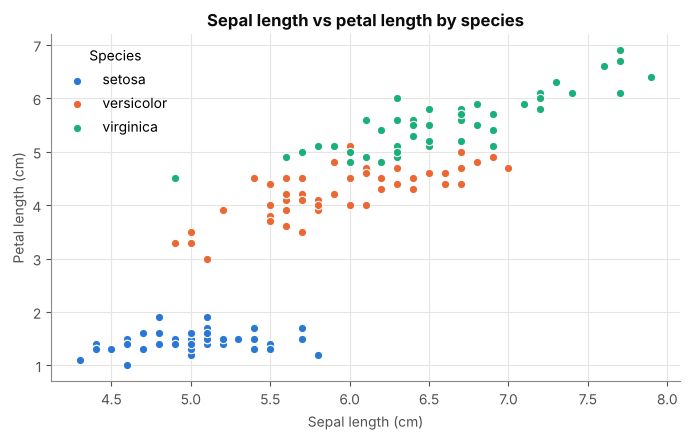

In [22]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, c in zip(iris.target_names, ["#2a78d6", "#eb6834", "#1baf7a"]):
    part = df[df.species == name]
    ax.scatter(part.sepal_length, part.petal_length, s=36, color=c, label=name,
               edgecolor="white", linewidth=0.8)
ax.set_xlabel("Sepal length (cm)"); ax.set_ylabel("Petal length (cm)")
ax.set_title("Sepal length vs petal length by species")
ax.legend(title="Species")
plt.tight_layout()
plt.savefig("figures/04_scatter_species.png", dpi=150, bbox_inches="tight")

## Conclusion
- Python's core types (list, tuple, dict, set) and NumPy/Pandas dtypes were demonstrated, along with nominal, ordinal, discrete and continuous data.
- Descriptive statistics showed petal length is bimodal (mean 3.76 < median 4.35) because *setosa* forms its own cluster.
- Petal length and width are very strongly correlated (r = 0.96).
- A simulation confirmed the Central Limit Theorem: sample means of a skewed population are approximately normal.
- Welch's t-test showed *versicolor* and *virginica* differ significantly in sepal length (p < 0.001).
- The notebook follows reproducibility, data-quality, documentation and version-control best practices.